In [ ]:
# set up environment
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
meta_data= pd.read_csv('/content/metadata_remane_original.csv')

In [ ]:
meta_data.head(10)

,ID,Year,Country,Continent,Gender,azm_sr,cip_sr,cro_sr,cfx_sr,tet_sr,pen_sr,Latitude,Longitude
0,101259,2015.0,United Kingdom,Europe,Male,Resistant,NaN,Sensitive,NaN,NaN,NaN,55.378051,-3.435973
1,101260,2015.0,United Kingdom,Europe,Male,Resistant,NaN,Sensitive,NaN,NaN,NaN,55.378051,-3.435973
2,101261,2015.0,United Kingdom,Europe,Female,Resistant,NaN,Sensitive,NaN,NaN,NaN,55.378051,-3.435973
3,101262,2015.0,United Kingdom,Europe,Male,Resistant,NaN,Sensitive,NaN,NaN,NaN,55.378051,-3.435973
4,101263,2015.0,United Kingdom,Europe,Male,Resistant,NaN,Sensitive,NaN,NaN,NaN,55.378051,-3.435973
5,101264,2015.0,United Kingdom,Europe,Male,Resistant,NaN,Sensitive,NaN,NaN,NaN,55.378051,-3.435973
6,101266,2015.0,United Kingdom,Europe,Male,Resistant,NaN,Sensitive,NaN,NaN,NaN,55.378051,-3.435973
7,110944,2015.0,United Kingdom,Europe,Female,Resistant,NaN,Sensitive,NaN,NaN,NaN,55.378051,-3.435973
8,110945,2015.0,United Kingdom,Europe,Male,Sensitive,NaN,Sensitive,NaN,NaN,NaN,55.378051,-3.435973
9,110946,2015.0,United Kingdom,Europe,Female,Sensitive,NaN,Sensitive,NaN,NaN,NaN,55.378051,-3.435973


# distribution of antiotic

<ipython-input-33-2f0e07fda4dc>:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=dist_anti_df.index, y='Count', data=dist_anti_df, palette=colors)


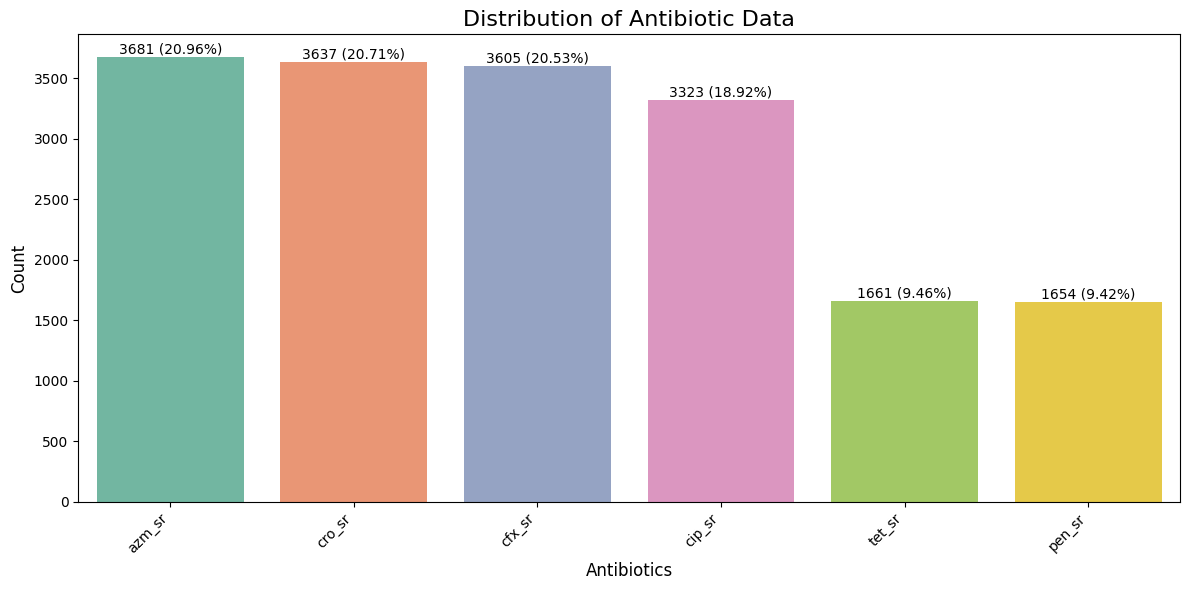

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Assuming meta_data is already defined and contains the antibiotics data

antibiotics = ['azm_sr', 'cip_sr', 'cro_sr', 'cfx_sr', 'tet_sr', 'pen_sr']

# Count non-null values
antibiotic_counts = meta_data[antibiotics].notna().sum()

# Calculate total and percentages
total = antibiotic_counts.sum()
percentages = (antibiotic_counts / total * 100).round(2)

# Create a DataFrame with counts and percentages
dist_anti_df = pd.DataFrame({
    'Count': antibiotic_counts,
    'Percentage': percentages
}).sort_values('Count', ascending=False)

plt.figure(figsize=(12, 6))

# Define the color palette
colors = sns.color_palette("Set2", n_colors=len(antibiotics))

# Create the bar plot and assign colors manually
ax = sns.barplot(x=dist_anti_df.index, y='Count', data=dist_anti_df, palette=colors)

# Customize the plot
plt.title('Distribution of Antibiotic Data', fontsize=16)
plt.xlabel('Antibiotics', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.xticks(rotation=45, ha='right')

# Add value labels on top of each bar
for i, v in enumerate(dist_anti_df['Count']):
    ax.text(i, v, f"{v} ({dist_anti_df['Percentage'].iloc[i]}%)", ha='center', va='bottom')

plt.tight_layout()

# Show the plot
plt.show()

# distribution of senstitive and resitance

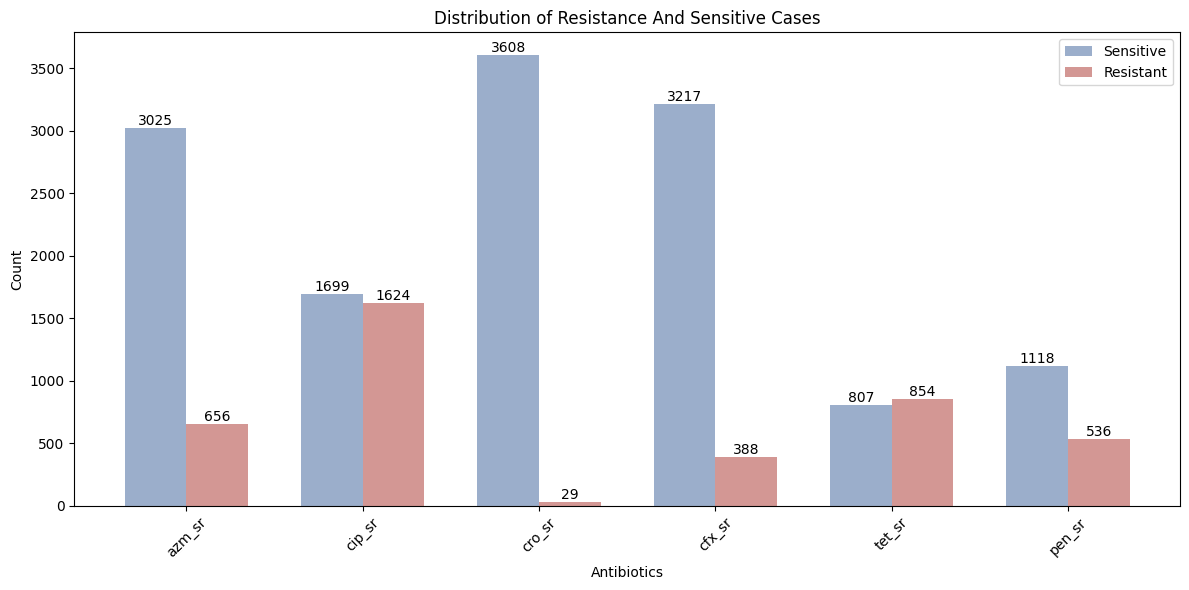

azm_sr:
  Sensitive: 3025
  Resistant: 656

cip_sr:
  Sensitive: 1699
  Resistant: 1624

cro_sr:
  Sensitive: 3608
  Resistant: 29

cfx_sr:
  Sensitive: 3217
  Resistant: 388

tet_sr:
  Sensitive: 807
  Resistant: 854

pen_sr:
  Sensitive: 1118
  Resistant: 536



In [ ]:
# Create a dictionary to store the counts
counts = {}
# Count the occurrences of each value for each antibiotic
for antibiotic in antibiotics:
    value_counts = meta_data[antibiotic].value_counts()
    counts[antibiotic] = {
        'Sensitive': value_counts.get('Sensitive', 0),
        'Resistant': value_counts.get('Resistant', 0)
    }

# Prepare data for plotting
antibiotics_names = list(counts.keys())
sensitive_counts = [counts[ab]['Sensitive'] for ab in antibiotics_names]
resistant_counts = [counts[ab]['Resistant'] for ab in antibiotics_names]

# Set up the plot
plt.figure(figsize=(12, 6))
x = range(len(antibiotics_names))
width = 0.35
color_palette = sns.color_palette("vlag", as_cmap=True)
# Create the bars
plt.bar([i - width/2 for i in x], sensitive_counts, width, label='Sensitive', color=color_palette(0.25))
plt.bar([i + width/2 for i in x], resistant_counts, width, label='Resistant', color=color_palette(0.75))

# Customize the plot
plt.xlabel('Antibiotics')
plt.ylabel('Count')
plt.title('Distribution of Resistance And Sensitive Cases')
plt.xticks(x, antibiotics_names, rotation=45)
plt.legend()

# Add value labels on top of each bar
for i, v in enumerate(sensitive_counts):
    plt.text(i - width/2, v, str(v), ha='center', va='bottom')
for i, v in enumerate(resistant_counts):
    plt.text(i + width/2, v, str(v), ha='center', va='bottom')

plt.tight_layout()
plt.show()
plt.close()

# Print the counts
for antibiotic, values in counts.items():
    print(f"{antibiotic}:")
    print(f"  Sensitive: {values['Sensitive']}")
    print(f"  Resistant: {values['Resistant']}")
    print()


# **continental distribution**

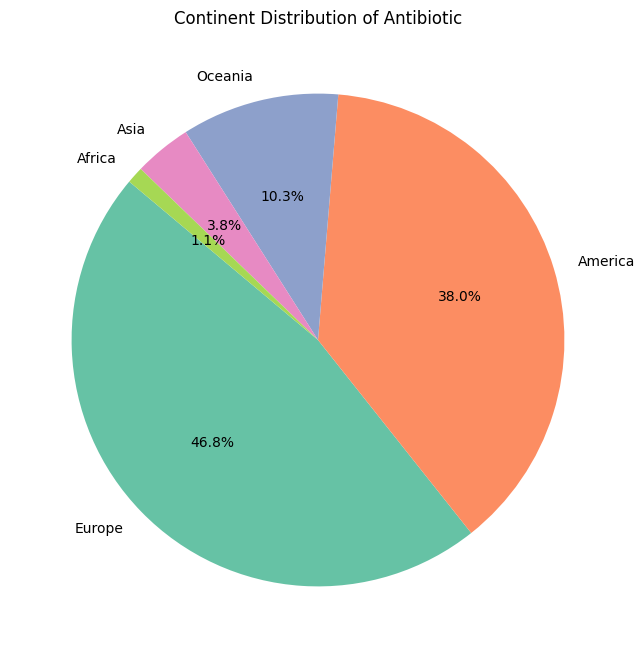

In [ ]:
continent_distribution = meta_data['Continent'].value_counts()

# Plotting the pie chart with the new color palette
plt.figure(figsize=(8, 8))

# Use sns.color_palette() to generate the color palette instead of calling the colors object
plt.pie(continent_distribution, labels=continent_distribution.index, autopct='%1.1f%%', startangle=140, colors=sns.color_palette("Set2", n_colors=len(continent_distribution)))

plt.title('Continent Distribution of Antibiotic')
plt.show()

# **demographic trends of sensitive resistance of each Azhithromicyn**

In [ ]:

# Filter out 'nan' values and create a new dataframe with year, continent, and azm_sr
def plot_trend_antibiotic(antibiotic):
  azm_df = meta_data[meta_data[antibiotic].notna()][['Year', 'Continent', antibiotic]]

  # Create pivot table
  pivot_df = pd.pivot_table(azm_df, index=['Year', 'Continent'], columns=antibiotic, aggfunc='size', fill_value=0)
  pivot_df = pivot_df.reset_index()

  # Create subplots for each continent
  continents = pivot_df['Continent'].unique()
  fig, axes = plt.subplots(3, 2, figsize=(20, 30))
  fig.suptitle(f'{antibiotic} Resistance Trends by Continent', fontsize=24, y=0.95)

  for i, continent in enumerate(continents):
      ax = axes[i // 2, i % 2]
      continent_data = pivot_df[pivot_df['Continent'] == continent]

      sns.lineplot(data=continent_data, x='Year', y='Resistant', ax=ax, label='Resistant', marker='o')
      sns.lineplot(data=continent_data, x='Year', y='Sensitive', ax=ax, label='Sensitive', marker='o')

      ax.set_title(f'{continent}', fontsize=18)
      ax.set_xlabel('Year', fontsize=14)
      ax.set_ylabel('Count', fontsize=14)
      ax.legend(fontsize=12)
      ax.tick_params(axis='both', which='major', labelsize=12)

      # Rotate x-axis labels for better readability
      ax.tick_params(axis='x', rotation=45)

  # Remove the empty subplot
  axes[2, 1].remove()

  plt.tight_layout(rect=[0, 0, 1, 0.95])
  plt.show()
  plt.close()

  # Calculate and print some statistics
  for continent in continents:
      continent_data = pivot_df[pivot_df['Continent'] == continent]
      total_resistant = continent_data['Resistant'].sum()
      total_sensitive = continent_data['Sensitive'].sum()
      total_cases = total_resistant + total_sensitive

      print(f"\
  {continent}:")
      print(f"Total cases: {total_cases}")
      print(f"Resistant cases: {total_resistant} ({total_resistant/total_cases*100:.2f}%)")
      print(f"Sensitive cases: {total_sensitive} ({total_sensitive/total_cases*100:.2f}%)")
      print(f"Year range: {continent_data['Year'].min()} - {continent_data['Year'].max()}")


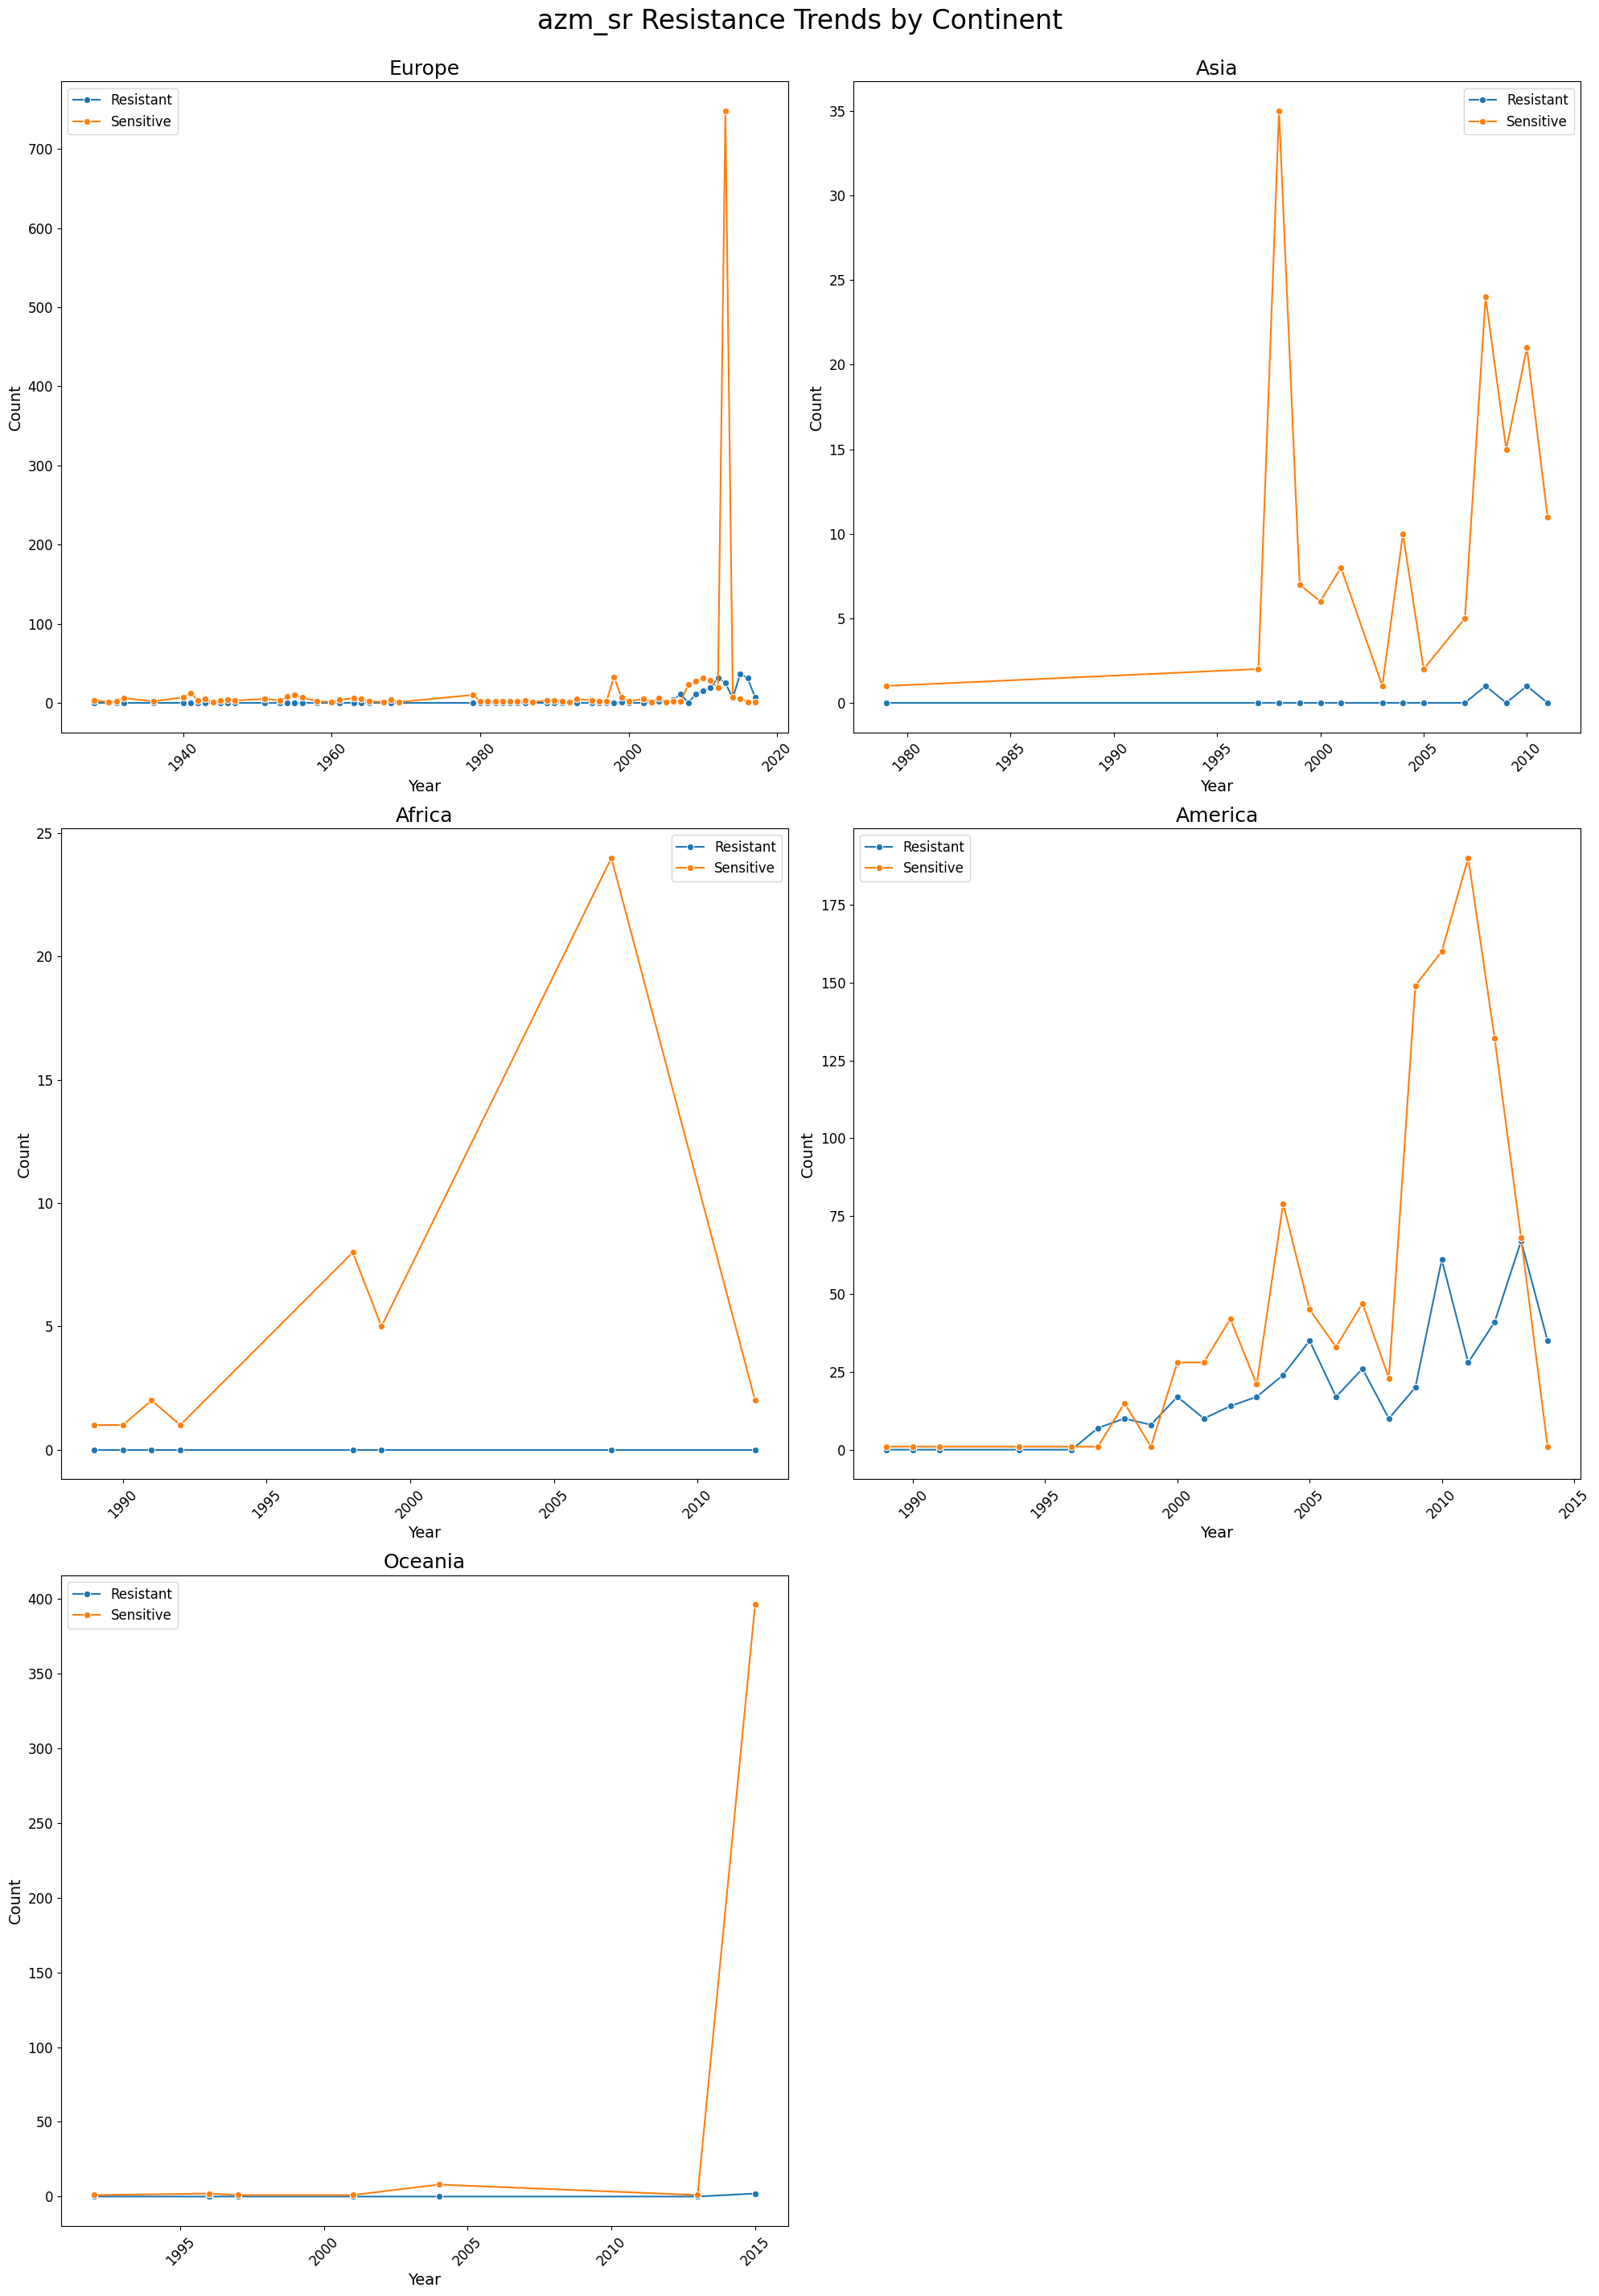

  Europe:
Total cases: 1310
Resistant cases: 202 (15.42%)
Sensitive cases: 1108 (84.58%)
Year range: 1928.0 - 2017.0
  Asia:
Total cases: 150
Resistant cases: 2 (1.33%)
Sensitive cases: 148 (98.67%)
Year range: 1979.0 - 2011.0
  Africa:
Total cases: 44
Resistant cases: 0 (0.00%)
Sensitive cases: 44 (100.00%)
Year range: 1989.0 - 2012.0
  America:
Total cases: 1515
Resistant cases: 447 (29.50%)
Sensitive cases: 1068 (70.50%)
Year range: 1989.0 - 2014.0
  Oceania:
Total cases: 412
Resistant cases: 2 (0.49%)
Sensitive cases: 410 (99.51%)
Year range: 1992.0 - 2015.0


In [ ]:
plot_trend_antibiotic('azm_sr')

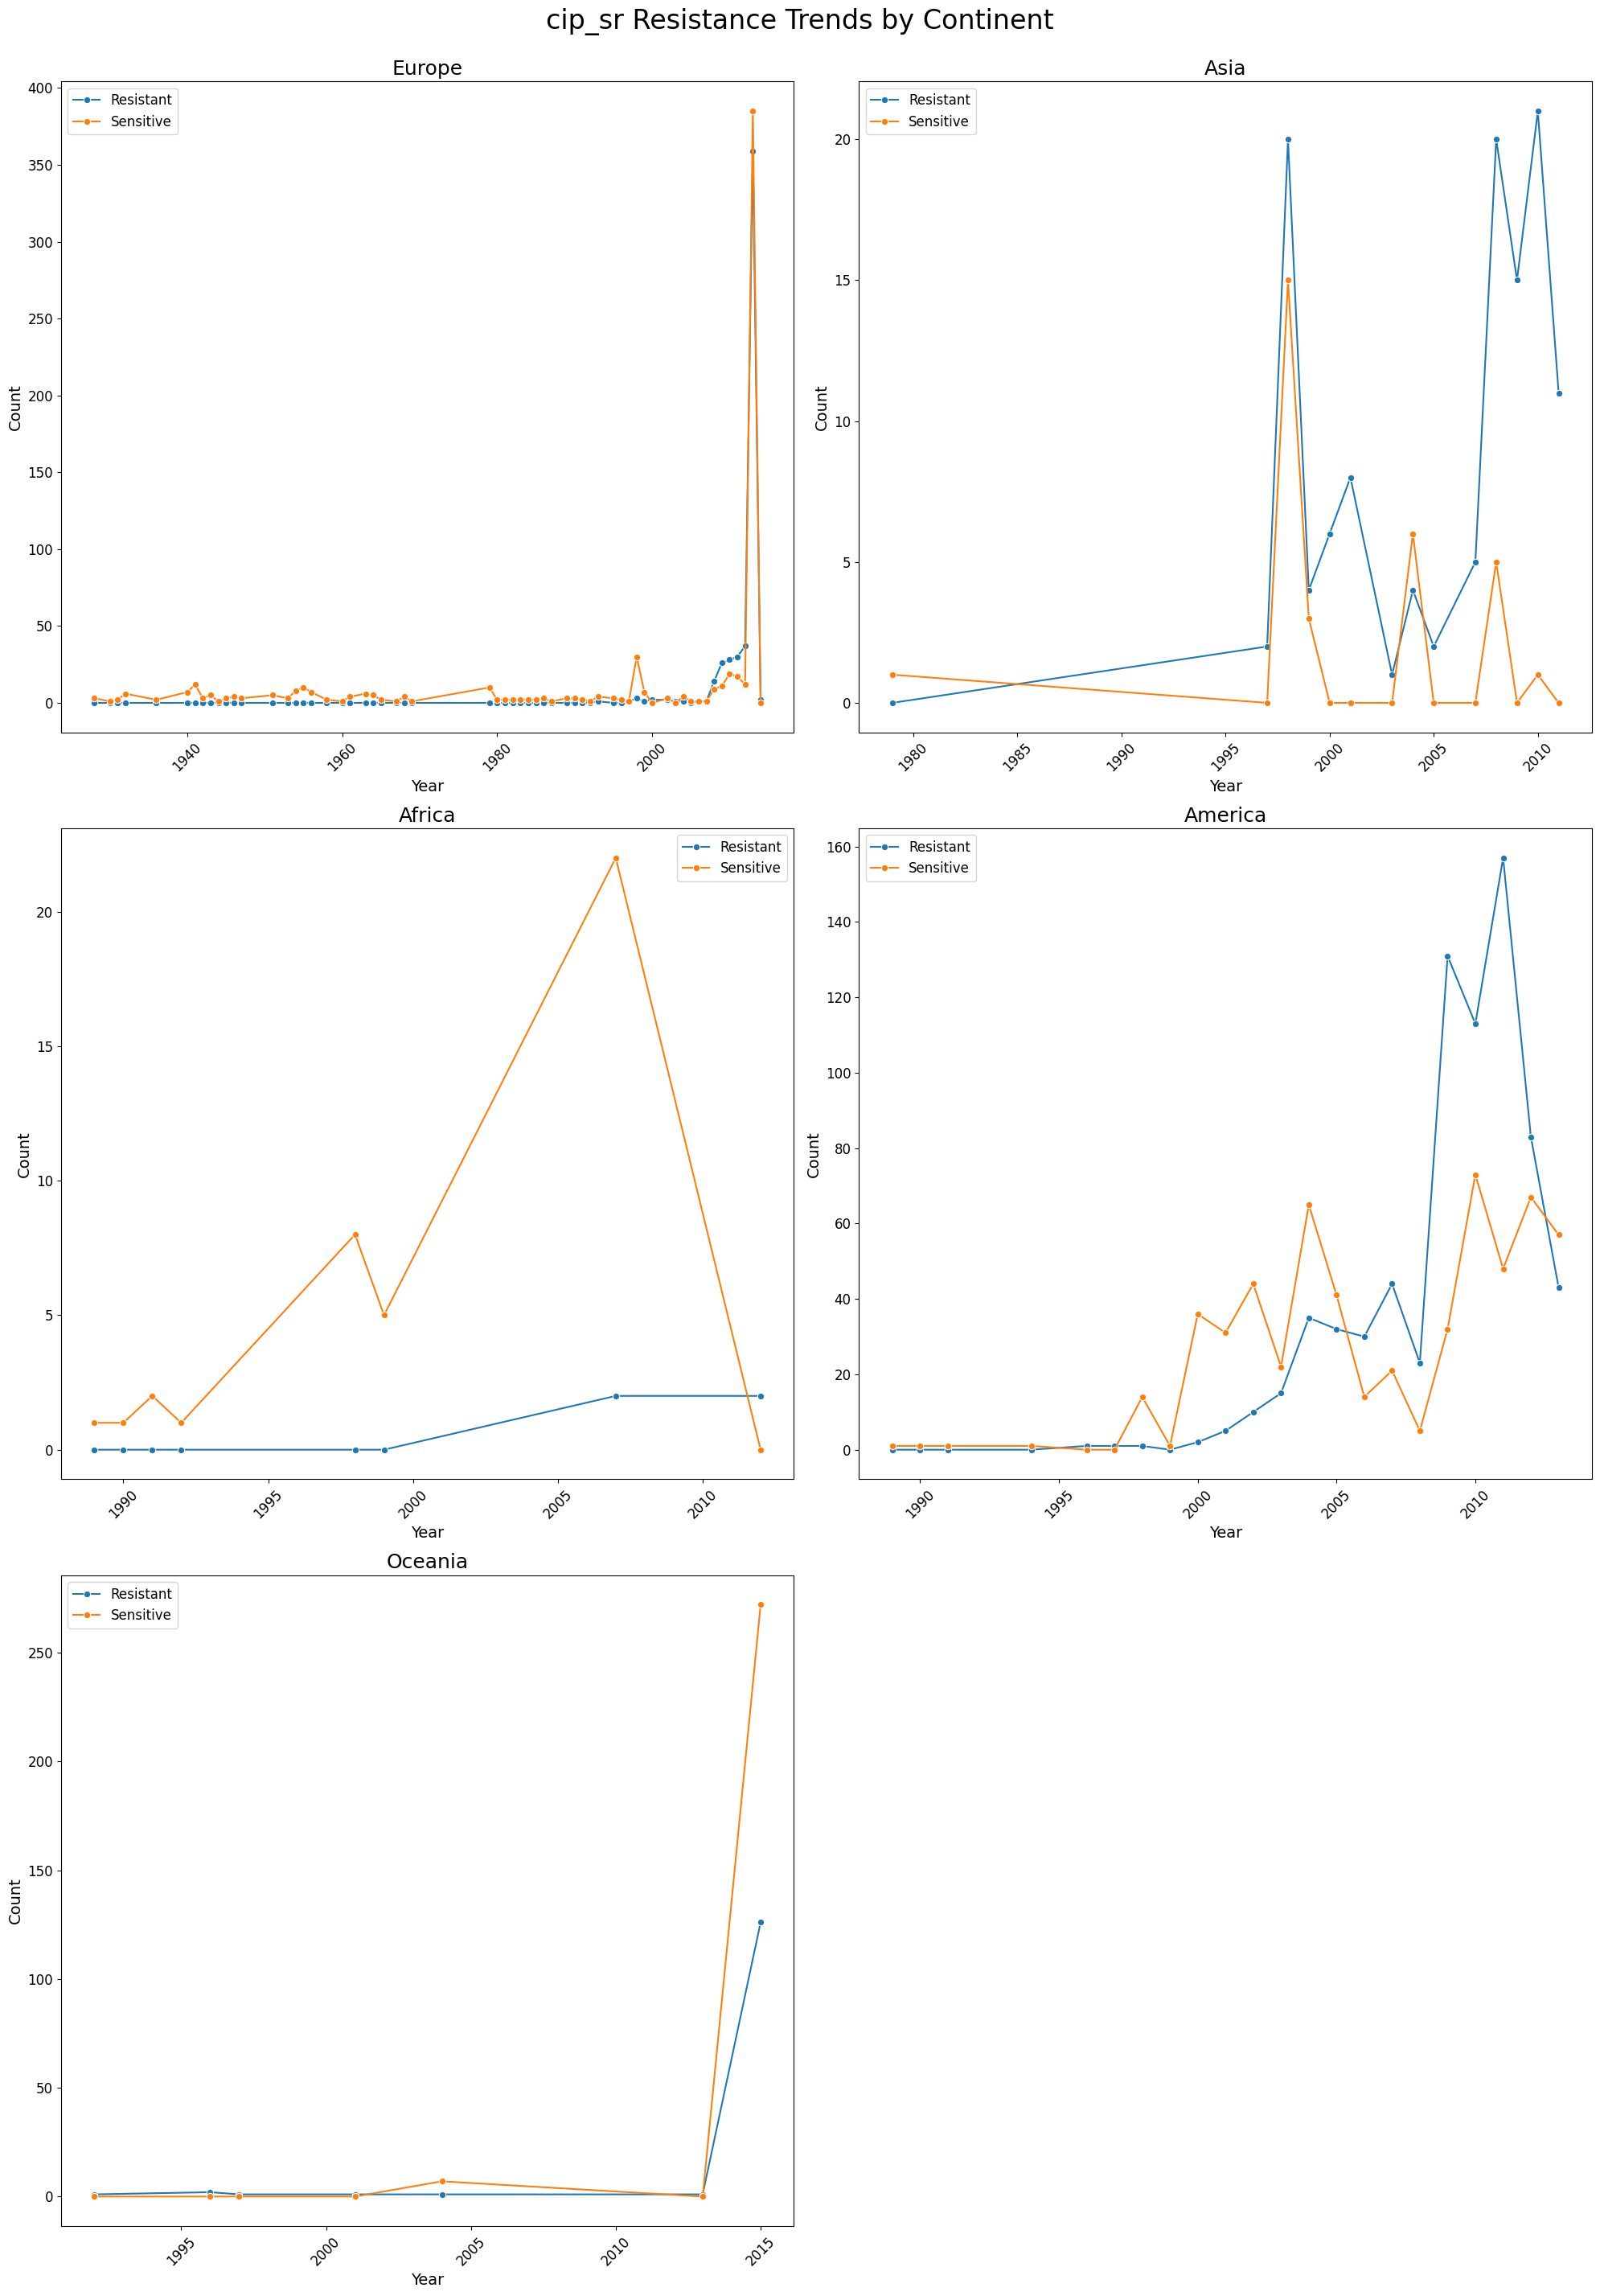

  Europe:
Total cases: 1166
Resistant cases: 510 (43.74%)
Sensitive cases: 656 (56.26%)
Year range: 1928.0 - 2014.0
  Asia:
Total cases: 150
Resistant cases: 119 (79.33%)
Sensitive cases: 31 (20.67%)
Year range: 1979.0 - 2011.0
  Africa:
Total cases: 44
Resistant cases: 4 (9.09%)
Sensitive cases: 40 (90.91%)
Year range: 1989.0 - 2012.0
  America:
Total cases: 1301
Resistant cases: 726 (55.80%)
Sensitive cases: 575 (44.20%)
Year range: 1989.0 - 2013.0
  Oceania:
Total cases: 412
Resistant cases: 133 (32.28%)
Sensitive cases: 279 (67.72%)
Year range: 1992.0 - 2015.0


In [ ]:
plot_trend_antibiotic('cip_sr')